• Open https://www.kaggle.com/datasets/yuchen0725/winedata
• Click on “New Notebook”
• Import Pandas and Seaborn (see the Seaborn cheat sheet)
• Read the data into a Pandas DataFrame

In [2]:
import pandas as pd

In [3]:
reviews=pd.read_csv(r"C:\Git_Packages\Marcell_Poerczi_BIPM2026\datasets\wine-reviews.csv", index_col=0)
print(reviews.duplicated().sum())
reviews=reviews.drop_duplicates(ignore_index=True)
print(reviews.duplicated().sum())
print(reviews.head())

9983
0
    country                                        description  \
0     Italy  Aromas include tropical fruit, broom, brimston...   
1  Portugal  This is ripe and fruity, a wine that is smooth...   
2        US  Tart and snappy, the flavors of lime flesh and...   
3        US  Pineapple rind, lemon pith and orange blossom ...   
4        US  Much like the regular bottling from 2012, this...   

                          designation  points  price           province  \
0                        Vulkà Bianco      87    NaN  Sicily & Sardinia   
1                            Avidagos      87   15.0              Douro   
2                                 NaN      87   14.0             Oregon   
3                Reserve Late Harvest      87   13.0           Michigan   
4  Vintner's Reserve Wild Child Block      87   65.0             Oregon   

              region_1           region_2         taster_name  \
0                 Etna                NaN       Kerin O’Keefe   
1              

1. Are there any missing data? What is the number of missing data for each column?

In [4]:
missing_cols = reviews.isna().sum()
missing_cols

country                     59
description                  0
designation              34545
points                       0
price                     8395
province                    59
region_1                 19560
region_2                 73219
taster_name              24917
taster_twitter_handle    29446
title                        0
variety                      1
winery                       0
dtype: int64

2. Filter only wines from France.

In [5]:
fr_reviews = reviews.loc[reviews["country"]=="France"]
fr_reviews.head()

,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
7,France,This dry and restrained wine offers spice in p...,NaN,87,24.0,Alsace,Alsace,NaN,Roger Voss,@vossroger,Trimbach 2012 Gewurztraminer (Alsace),Gewürztraminer,Trimbach
9,France,This has great depth of flavor with its fresh ...,Les Natures,87,27.0,Alsace,Alsace,NaN,Roger Voss,@vossroger,Jean-Baptiste Adam 2012 Les Natures Pinot Gris...,Pinot Gris,Jean-Baptiste Adam
11,France,"This is a dry wine, very spicy, with a tight, ...",NaN,87,30.0,Alsace,Alsace,NaN,Roger Voss,@vossroger,Leon Beyer 2012 Gewurztraminer (Alsace),Gewürztraminer,Leon Beyer
30,France,Red cherry fruit comes laced with light tannin...,Nouveau,86,NaN,Beaujolais,Beaujolais-Villages,NaN,Roger Voss,@vossroger,Domaine de la Madone 2012 Nouveau (Beaujolais...,Gamay,Domaine de la Madone
42,France,"This is a festive wine, with soft, ripe fruit ...",Nouveau,86,9.0,Beaujolais,Beaujolais,NaN,Roger Voss,@vossroger,Henry Fessy 2012 Nouveau (Beaujolais),Gamay,Henry Fessy


3. Show the first five rows for the columns “taster” and “points”.

In [6]:
taster_five = reviews[["taster_name","points"]].drop_duplicates(subset="taster_name").head(5).reset_index(drop=True)
taster_five


,taster_name,points
0,Kerin O’Keefe,87
1,Roger Voss,87
2,Paul Gregutt,87
3,Alexander Peartree,87
4,Michael Schachner,87


4. How often has each taster reviewed a wine?

In [7]:
taster_activitiy = reviews.loc[reviews["taster_name"].isin(taster_five["taster_name"])].groupby("taster_name").size()
taster_activitiy

taster_name
Alexander Peartree      383
Kerin O’Keefe          9697
Michael Schachner     14046
Paul Gregutt           8868
Roger Voss            23560
dtype: int64

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

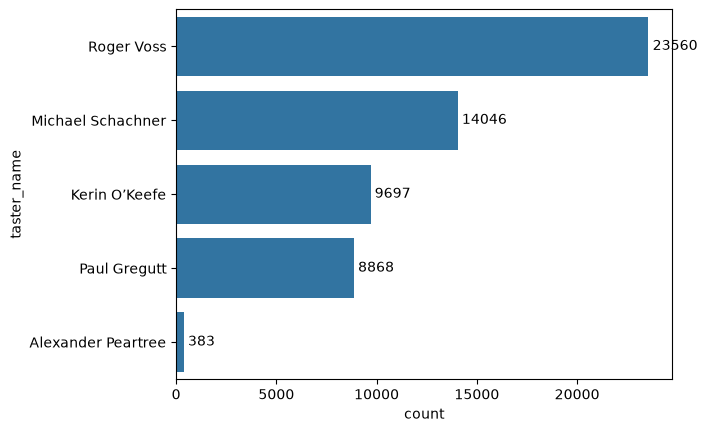

In [8]:
filter_for_five = reviews.loc[reviews["taster_name"].isin(taster_five["taster_name"])]
ax = sns.countplot(filter_for_five,
              y = filter_for_five["taster_name"],
              order = filter_for_five["taster_name"].value_counts(ascending=False).index)
ax.bar_label(ax.containers[0], padding=3)
ax.set_xticks(range(0, taster_activitiy.max() + 1,5000))
plt.show()

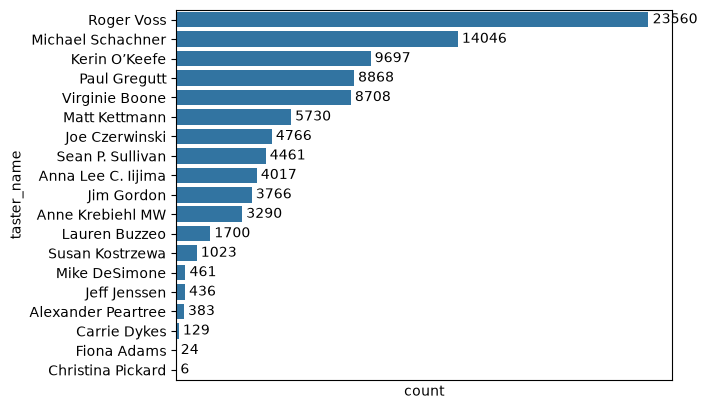

In [14]:
ax_b= sns.countplot(reviews,
              y = reviews["taster_name"],
              order = reviews["taster_name"].value_counts(ascending=False).index)
ax_b.bar_label(ax_b.containers[0], padding=3)
taster_activitiy_b = reviews["taster_name"].count()
ax_b.set_xticks([])
plt.show()

6. Visualize the distribution of the points (distribution of one numeric variable). Try asecond plot type for the same question. Which one do you find more useful?

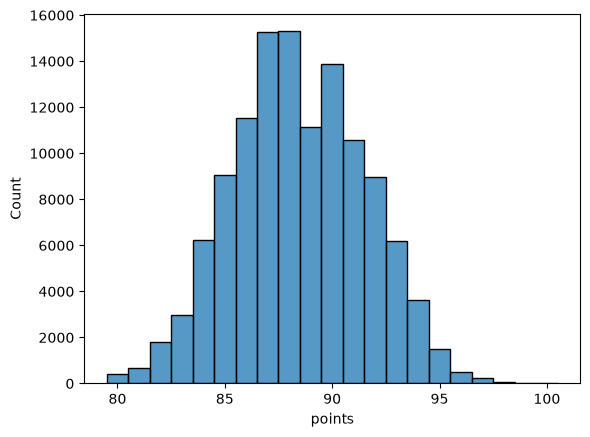

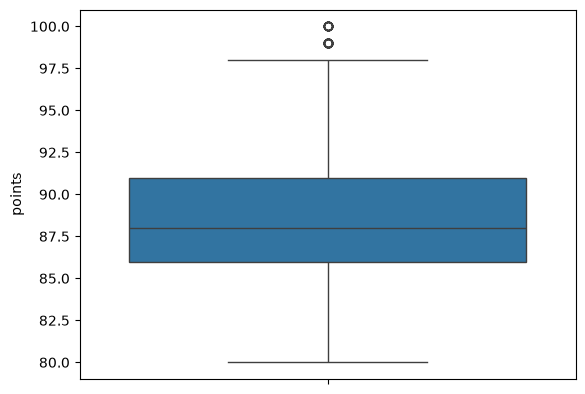

In [32]:
sns.histplot(reviews["points"],discrete=True)
plt.show()
sns.boxplot(reviews["points"])
plt.show()

7. What is the highest price?8. What wine has the highest price?

In [37]:
highest_price = reviews["price"].max()
highest_price_wine = reviews.loc[reviews["price"] == highest_price,"title"]
print(highest_price, highest_price_wine)

3300.0 76317    Château les Ormes Sorbet 2013  Médoc
Name: title, dtype: str


9. What wines have a more than-average rating (points) sorted in ascending order forthe price?

In [40]:
avg_points = reviews["points"].mean()
better_wines = reviews.loc[reviews["points"]>avg_points,["title","points","price"]].sort_values("price", ascending= True)
print(avg_points, better_wines.head(10))

88.44223589025569                                                     title  points  price
41819    Borsao 2008 Monte Oton Garnacha (Campo de Borja)      89    7.0
61159   Hogue 2008 Red Table Wine Red (Columbia Valley...      89    7.0
33955   Herdade dos Machados 2012 Toutalga Red (Alente...      91    7.0
90295   Caves Velhas 2013 D. Fuas Reserva Red (Terras ...      89    7.0
106989                   Borsao 2008 Red (Campo de Borja)      89    8.0
43305     Château Labrousse 2015  Blaye Côtes de Bordeaux      89    8.0
72235   Rothbury Estate 2001 Chardonnay (South Eastern...      90    8.0
33907                    Borsao 2009 Red (Campo de Borja)      89    8.0
6757         Oak Grove 2007 Reserve Viognier (California)      89    8.0
101753  StoneCap 2010 Estate Grown Riesling (Columbia ...      89    8.0


10. Visualize the relationship between price and points with a regression line(relationship between numerical variables). Is there any relationship?

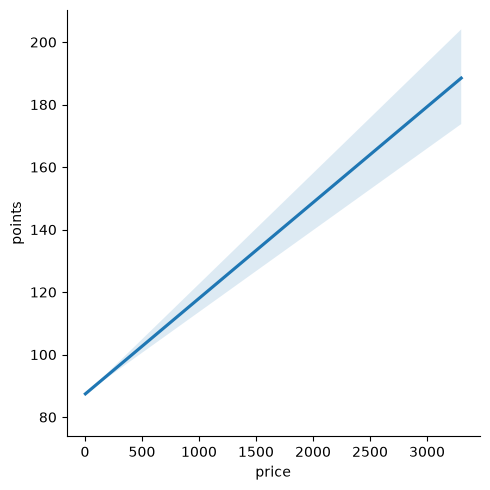

np.float64(0.4165339833464545)

In [58]:
import numpy as np
sns.regression.lmplot(reviews, x = "price", y= "points", markers="none")
rel_strength=reviews["price"].corr(reviews["points"])
plt.show()
rel_strength


12. Compare the distribution of points between the tasters (relationship betweencategorical and numerical variables). Which taster rates most generously, which moststrictly? (Tip: put the tasters on the y-axis so the names are readable)

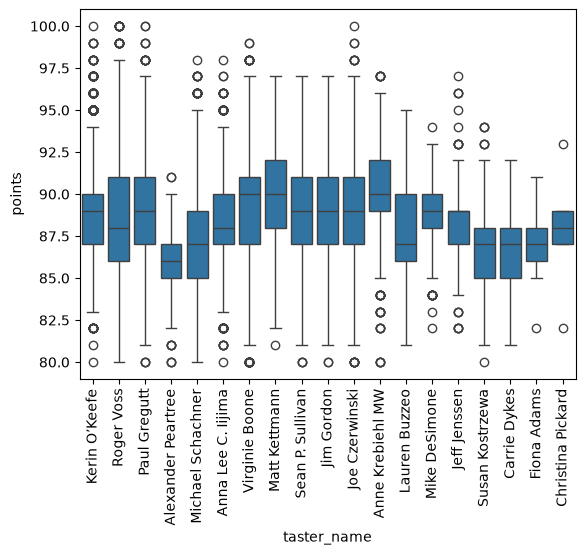

In [62]:
sns.boxplot(reviews, x="taster_name", y="points")
plt.tick_params("x",labelrotation = 90)

Alexander Peartree is the worst

13. For the wines from France, show each wine as a point with its price and points(relationship between numerical variables). Color the points by province with thehue parameter. Which province has the most expensive wines?14. Change the look of your plots with sns.set_theme(style="whitegrid")and try a different color palette (palette parameter). Which style do you find theeasiest to read?

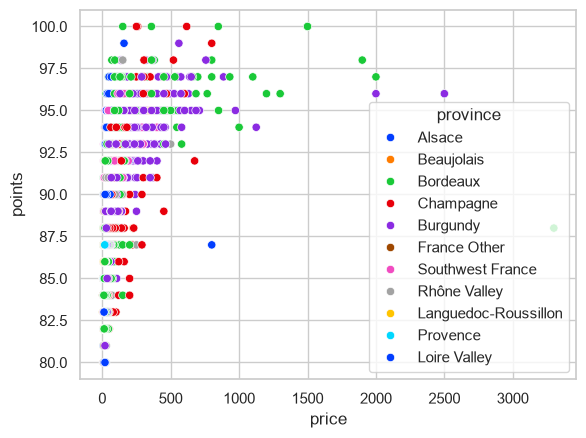

In [93]:
sns.set_theme(style= "whitegrid")
sns.scatterplot(fr_reviews, x = "price" , y = "points" , hue = "province",palette="bright")
plt.show()

Burgundy and Bordeux wines are the most expensive. I find bright the easiest to read as there are a lot of datapoints stacked on each other.

Switch between Driver and Navigator after each question in your Pair Programming session.For the plots, use the Seaborn cheat sheet: first decide what kind of variables you want toshow, then pick a suitable plot.2. Filter only wines from France.3. Show the first five rows for the columns “taster” and “points”.4. How often has each taster reviewed a wine?5. Visualize how often each taster reviewed a wine (distribution of a categoricalvariable).6. Visualize the distribution of the points (distribution of one numeric variable). Try asecond plot type for the same question. Which one do you find more useful?7. What is the highest price?8. What wine has the highest price?9. What wines have a more than-average rating (points) sorted in ascending order forthe price?10. Visualize the relationship between price and points with a regression line(relationship between numerical variables). Is there any relationship?11. Calculate the correlation between price and points (there is a Pandas method forthis)12. Compare the distribution of points between the tasters (relationship betweencategorical and numerical variables). Which taster rates most generously, which moststrictly? (Tip: put the tasters on the y-axis so the names are readable)13. For the wines from France, show each wine as a point with its price and points(relationship between numerical variables). Color the points by province with thehue parameter. Which province has the most expensive wines?14. Change the look of your plots with sns.set_theme(style="whitegrid")and try a different color palette (palette parameter). Which style do you find theeasiest to read?